In [1]:
### CELL [code] — 1. Setup & imports
import os, math
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2
from plyfile import PlyData
from scipy.spatial.transform import Rotation as Rsc

torch.set_grad_enabled(False)

import roma
try:
    from pytorch3d.ops import efficient_pnp, corresponding_points_alignment
    HAS_P3D = True
except Exception as e:
    HAS_P3D = False; print("pytorch3d not available:", e)
try:
    import pypose as pp
    HAS_PYPOSE = True
except Exception:
    HAS_PYPOSE = False
try:
    import open3d as o3d
    HAS_O3D = True
except Exception:
    HAS_O3D = False

torch.manual_seed(0); np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype  = torch.float64    # double precision for solver-debug sanity
print(device, dtype, "p3d=", HAS_P3D, "pypose=", HAS_PYPOSE, "o3d=", HAS_O3D)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
cuda torch.float64 p3d= True pypose= True o3d= True


In [2]:
### CELL [markdown] — 2. Load a 3DGS .ply
# Inria/FastGS layout: x,y,z, nx,ny,nz, f_dc_0..2, f_rest_0..(3*((deg+1)^2-1)-1),
# opacity (logit), scale_0..2 (log), rot_0..3 (quat in w,x,y,z, unnormalized).
# Activations: scaling = exp(scale), opacity = sigmoid(opacity), rot = q/||q||.
# Σ^W = R · diag(exp(s))^2 · R^T.

In [3]:
### CELL [code] — 2. Load a 3DGS .ply
PLY_PATH = "/leonardo_work/IscrC_EditGS/repos/FastGS/output/kitchen/point_cloud/iteration_30000/point_cloud.ply"  # FILL ME

from scene import Scene, GaussianModel
from utils.general_utils import build_rotation

gaussians = GaussianModel(sh_degree=3)

from argparse import ArgumentParser
from arguments import ModelParams, PipelineParams, OptimizationParams
import torch
import matplotlib.pyplot as plt

parser = ArgumentParser()
lp = ModelParams(parser)
op = OptimizationParams(parser)
pp = PipelineParams(parser)

args = parser.parse_args(args=[
    "-s", "/leonardo_work/IscrC_EditGS/datasets/mip360/kitchen",
    "-i", "images",
    "--eval"
])

dataset = lp.extract(args)
opt = op.extract(args)
pipe = pp.extract(args)
bg_color = [1, 1, 1] if dataset.white_background else [0, 0, 0]
background = torch.tensor(bg_color, dtype=torch.float32, device="cuda")
scene = Scene(dataset, gaussians)

Reading camera 279/279
Loading Training Cameras
[ INFO ] Encountered quite large input images (>1.6K pixels width), rescaling to 1.6K.
 If this is not desired, please explicitly specify '--resolution/-r' as 1
Loading Test Cameras
Number of points at initialisation :  241367


In [4]:
gaussians.load_ply(PLY_PATH)


xyzs = gaussians.get_xyz.double()
scales = gaussians.get_scaling.double()
quats = gaussians.get_rotation.double()
covariances = gaussians.get_covariance().double()
rots = build_rotation(quats).double()  # convert unnormalized quaternions to rotation matrices

#print the shapes of everything
print("xyz shape:", xyzs.shape)
print("quats shape:", quats.shape)
print("scales shape:", scales.shape)
print("rots shape:", rots.shape)
print("covariance shape:", covariances.shape)
print("covariance[0]:", covariances[0])

xyz shape: torch.Size([379675, 3])
quats shape: torch.Size([379675, 4])
scales shape: torch.Size([379675, 3])
rots shape: torch.Size([379675, 3, 3])
covariance shape: torch.Size([379675, 6])
covariance[0]: tensor([ 7.0207e-05,  3.0188e-05, -2.1859e-07,  1.6221e-05,  1.8923e-06,
         3.8108e-05], device='cuda:0', dtype=torch.float64)


In [5]:
camera = scene.getTrainCameras()[0]
w2v = camera.world_view_transform
w2v = camera.world_view_transform.double()   # ← cast here

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0536013].


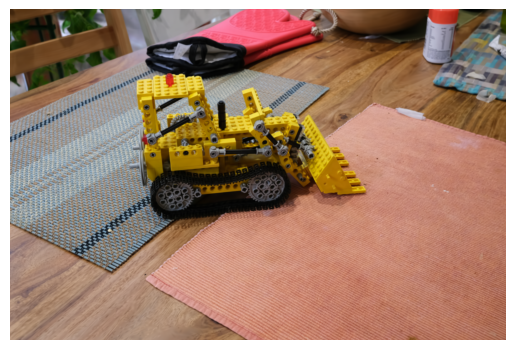

In [6]:
#render the camera
from gaussian_renderer import render_fastgs



render_pkg = render_fastgs(camera, gaussians, pipe, background, opt.mult)
image, viewspace_point_tensor,  = render_pkg["render"], render_pkg["viewspace_points"], 
visibility_filter, radii =  render_pkg["visibility_filter"], render_pkg["radii"]

#show the rendered image
plt.imshow(image.cpu().detach().numpy().transpose(1, 2, 0))
plt.axis("off")
plt.show()

In [7]:
print(w2v.shape)
R_cw = w2v[:3, :3].T     # because it's stored transposed
t_cw = w2v[3, :3]        # translation is in the last ROW after the transpose
xyzs_C = xyzs @ R_cw.T + t_cw

print(xyzs_C[:10])

torch.Size([4, 4])
tensor([[-0.6306, -0.6900,  3.8841],
        [-1.4163,  1.1537,  2.8708],
        [-1.7663, -0.0621,  4.6772],
        [-0.3735, -0.4624,  4.3531],
        [-0.0133, -0.2710,  4.7011],
        [ 0.7904,  0.0820,  4.3786],
        [ 0.8929, -1.4519,  6.8759],
        [ 0.1968, -0.3869,  4.2507],
        [ 0.1106, -0.5231,  4.4704],
        [-0.0100, -0.3211,  3.9837]], device='cuda:0', dtype=torch.float64)


In [8]:
### CELL [code] — 4. Build K from camera FoV
import math
import numpy as np

H, W = camera.image_height, camera.image_width
fx = W / (2.0 * math.tan(camera.FoVx / 2.0))
fy = H / (2.0 * math.tan(camera.FoVy / 2.0))
cx, cy = W / 2.0, H / 2.0
K = torch.tensor([[fx, 0, cx],
                  [0, fy, cy],
                  [0,  0,  1]], dtype=torch.float64, device="cuda")
K_np = K.cpu().numpy().astype(np.float64)
print("Image size:", H, W, "  K:\n", K_np)

Image size: 1067 1600   K:
 [[1.65988130e+03 0.00000000e+00 8.00000000e+02]
 [0.00000000e+00 1.66407221e+03 5.33500000e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


In [9]:
print("min z:", xyzs_C[:,2].min().item(), " max z:", xyzs_C[:,2].max().item())
print("frac z>0:", (xyzs_C[:,2] > 0).float().mean().item())

proj = xyzs_C @ (K.T).double()
uv_all = proj[:, :2] / proj[:, 2:3]

in_front = xyzs_C[:, 2] > 1e-3
in_img = (uv_all[:,0] >= 0) & (uv_all[:,0] < W) & (uv_all[:,1] >= 0) & (uv_all[:,1] < H)
visible = in_front & in_img
print(f"visible: {visible.sum().item()}/{len(visible)}")

min z: -54.50510453439978  max z: 83.83901182933545
frac z>0: 0.9684256315231323
visible: 297026/379675


In [10]:
def expand_cov6_to_3x3(cov6):
    N = cov6.shape[0]
    Sigma = torch.zeros(N, 3, 3, dtype=cov6.dtype, device=cov6.device)
    Sigma[:,0,0] = cov6[:,0]; Sigma[:,0,1] = cov6[:,1]; Sigma[:,0,2] = cov6[:,2]
    Sigma[:,1,0] = cov6[:,1]; Sigma[:,1,1] = cov6[:,3]; Sigma[:,1,2] = cov6[:,4]
    Sigma[:,2,0] = cov6[:,2]; Sigma[:,2,1] = cov6[:,4]; Sigma[:,2,2] = cov6[:,5]
    return Sigma


Sigma_W = expand_cov6_to_3x3(covariances)

# Sanity: rebuild Σ^W from rots and scales and compare
Sigma_W_check = torch.einsum('nij,nj,nkj->nik', rots, scales**2, rots)
err = (Sigma_W - Sigma_W_check).abs().max().item()
print("max |Σ_from_cov6 - Σ_from_RSR^T| =", err)
print("Sigma_W shape:", Sigma_W.shape)

max |Σ_from_cov6 - Σ_from_RSR^T| = 0.00011052075075212997
Sigma_W shape: torch.Size([379675, 3, 3])


In [11]:
### CELL [code] — 7. Generate GT correspondences for a random subset of visible Gaussians
K_PTS = 200
visible_idx = torch.where(visible)[0]
perm = torch.randperm(len(visible_idx), device="cuda")[:K_PTS]
sel = visible_idx[perm]

# World-frame quantities (from the map)
mu_W   = xyzs[sel]                              # (K,3)
R_W    = rots[sel]                              # (K,3,3)
Sig_W  = Sigma_W[sel]                           # (K,3,3)

# Camera-frame GT (what the network should ideally predict per pixel)
mu_C   = mu_W @ R_cw.T + t_cw                   # (K,3)
R_C    = torch.einsum('ij,njk->nik', R_cw, R_W) # (K,3,3)
Sig_C  = torch.einsum('ij,njk,lk->nil', R_cw, Sig_W, R_cw)  # (K,3,3)

# Pixel coords
proj   = mu_C @ K.T
uv     = proj[:, :2] / proj[:, 2:3]             # (K,2)

# Verify reprojection consistency against the full-set projection from cell 5
print("max reproj inconsistency:", (uv - uv_all[sel]).abs().max().item())
print("Shapes — mu_W:", mu_W.shape, " mu_C:", mu_C.shape, " uv:", uv.shape,
      " R_W:", R_W.shape, " R_C:", R_C.shape, " Sig_C:", Sig_C.shape)

# Numpy copies for OpenCV solvers later
mu_W_np = mu_W.detach().cpu().numpy().astype(np.float64)
mu_C_np = mu_C.detach().cpu().numpy().astype(np.float64)
uv_np   = uv.detach().cpu().numpy().astype(np.float64)
R_cw_np = R_cw.double().cpu().numpy()   # cast to float64 ON TENSOR, then to numpy
t_cw_np = t_cw.double().cpu().numpy()

max reproj inconsistency: 0.0
Shapes — mu_W: torch.Size([200, 3])  mu_C: torch.Size([200, 3])  uv: torch.Size([200, 2])  R_W: torch.Size([200, 3, 3])  R_C: torch.Size([200, 3, 3])  Sig_C: torch.Size([200, 3, 3])


In [12]:
### CELL [code] — 8. PnP solvers (3D world points ↔ 2D pixels)

def solve_pnp_opencv(world_pts, pix_pts, K_np, flag=cv2.SOLVEPNP_SQPNP):
    """OpenCV PnP. Returns (ok, R_cw, t_cw) in column-vector convention."""
    op_pts = world_pts.astype(np.float64).reshape(-1, 1, 3)
    ip_pts = pix_pts.astype(np.float64).reshape(-1, 1, 2)
    ok, rvec, tvec = cv2.solvePnP(op_pts, ip_pts, K_np, distCoeffs=None, flags=flag)
    R, _ = cv2.Rodrigues(rvec)
    return ok, R, tvec.reshape(3)

def solve_pnp_pytorch3d(world_pts, pix_pts, K_intr):
    """
    PyTorch3D EPnP. Expects 2D points in NDC (K^-1 applied), row-vector convention.
    Internally solves: y = Proj(x R + T), then we transpose R to match column convention.
    """
    if not HAS_P3D:
        raise RuntimeError("pytorch3d not available")
    K_inv = np.linalg.inv(K_intr)
    homo  = np.concatenate([pix_pts, np.ones_like(pix_pts[:, :1])], axis=1)
    ndc   = (homo @ K_inv.T)[:, :2]
    x = torch.tensor(world_pts[None], dtype=torch.float64, device="cuda")
    y = torch.tensor(ndc[None],       dtype=torch.float64, device="cuda")
    sol = efficient_pnp(x, y)
    R_p3d = sol.R[0].cpu().numpy()
    T_p3d = sol.T[0].cpu().numpy()
    # Convert row-vector (x R + T) to column-vector (R_cw x + t_cw)
    return True, R_p3d.T, T_p3d

In [13]:
### CELL [code] — 9. Procrustes (3D-3D, centers only) — custom torch SVD

def solve_procrustes_torch(X_W, X_C, w=None):
    """
    Solves μ^C = R_cw · μ^W + t_cw in closed form via SVD (Kabsch/Umeyama).
    
    X_W, X_C: (K,3) tensors in world and camera frames.
    w: optional (K,) scalar weights (defaults to uniform).
    Returns R_cw (3,3), t_cw (3,).
    """
    if w is None:
        w = torch.ones(X_W.shape[0], dtype=X_W.dtype, device=X_W.device)
    w = w / w.sum()
    
    # Weighted centroids
    xb = (w[:, None] * X_W).sum(0)
    yb = (w[:, None] * X_C).sum(0)
    
    # Centered points
    Xc = X_W - xb
    Yc = X_C - yb
    
    # Cross-covariance H = Σ w_k (X_W_k - x̄)(X_C_k - ȳ)^T
    H = (Xc * w[:, None]).T @ Yc                       # (3,3)
    
    # SVD
    U, S, Vh = torch.linalg.svd(H)
    V = Vh.T
    
    # Reflection fix: enforce det(R) = +1
    d = torch.sign(torch.linalg.det(V @ U.T))
    D = torch.diag(torch.stack([torch.ones_like(d), torch.ones_like(d), d]))
    
    R = V @ D @ U.T
    t = yb - R @ xb
    return R, t

In [14]:
### CELL [code] — 10. Rotation-only Procrustes (rotation averaging from per-Gaussian R correspondences)

def solve_rotation_only_torch(R_W, R_C, w=None):
    """
    Given pairs (R_W_k, R_C_k) with R_C_k = R_cw · R_W_k,
    solves R_cw = argmin_R Σ w_k ‖R · R_W_k - R_C_k‖_F²
    via SVD of M = Σ w_k R_C_k · R_W_k^T.

    R_W, R_C: (K,3,3) tensors. w: optional (K,) scalar weights.
    Returns R_cw (3,3).
    """
    if w is None:
        w = torch.ones(R_W.shape[0], dtype=R_W.dtype, device=R_W.device)
    
    # M = Σ w_k R_C_k R_W_k^T
    M = torch.einsum('k,kij,klj->il', w, R_C, R_W)
    
    # SVD
    U, S, Vh = torch.linalg.svd(M)
    
    # Reflection fix
    d = torch.sign(torch.linalg.det(U @ Vh))
    D = torch.diag(torch.stack([torch.ones_like(d), torch.ones_like(d), d]))
    
    return U @ D @ Vh

In [15]:
### CELL [code] — 11. Error metrics

def rot_err_deg(R1, R2):
    """Geodesic rotation error in degrees: θ = arccos((tr(R1^T R2) - 1) / 2)."""
    R1 = R1.detach().cpu() if torch.is_tensor(R1) else torch.as_tensor(R1)
    R2 = R2.detach().cpu() if torch.is_tensor(R2) else torch.as_tensor(R2)
    R1, R2 = R1.float(), R2.float()
    trace = (R1.T @ R2).diagonal().sum()
    cos = ((trace - 1) / 2).clamp(-1 + 1e-7, 1 - 1e-7)
    return float(torch.acos(cos) * 180.0 / math.pi)

def trans_err(t1, t2):
    """Euclidean translation error in scene units."""
    a = t1.detach().cpu().numpy() if torch.is_tensor(t1) else np.asarray(t1)
    b = t2.detach().cpu().numpy() if torch.is_tensor(t2) else np.asarray(t2)
    return float(np.linalg.norm(a - b))

def reproj_err_px(R, t, X_W_np, uv_np, K_np):
    """Mean reprojection error in pixels."""
    Xc = X_W_np @ R.T + t.reshape(1, 3)
    proj = Xc @ K_np.T
    proj = proj[:, :2] / proj[:, 2:3]
    return float(np.linalg.norm(proj - uv_np, axis=1).mean())

In [16]:
### CELL [code] — 12. ZERO-NOISE SANITY CHECK
# All solvers should hit ~machine precision since we feed them perfect GT correspondences.

# --- OpenCV PnP (3D-2D) ---
ok, R_cv, t_cv = solve_pnp_opencv(mu_W_np, uv_np, K_np, cv2.SOLVEPNP_SQPNP)
print(f"CV2 SQPnP    : rot={rot_err_deg(R_cv, R_cw_np):.3e}°  "
      f"trans={trans_err(t_cv, t_cw_np):.3e}  "
      f"reproj={reproj_err_px(R_cv, t_cv, mu_W_np, uv_np, K_np):.3e} px")


# --- PyTorch3D EPnP (3D-2D, differentiable) ---
if HAS_P3D:
    _, R_p3d, t_p3d = solve_pnp_pytorch3d(mu_W_np, uv_np, K_np)
    print(f"P3D EPnP     : rot={rot_err_deg(R_p3d, R_cw_np):.3e}°  "
          f"trans={trans_err(t_p3d, t_cw_np):.3e}")


# --- Procrustes (3D-3D, centers only) ---
R_pr, t_pr = solve_procrustes_torch(mu_W.double(), mu_C.double())
print(f"Procrustes   : rot={rot_err_deg(R_pr, R_cw):.3e}°  "
      f"trans={trans_err(t_pr, t_cw):.3e}")


# --- Rotation-only Procrustes (from per-Gaussian R correspondences) ---
R_rot = solve_rotation_only_torch(R_W.double(), R_C.double())
print(f"Rot-only SVD : rot={rot_err_deg(R_rot, R_cw):.3e}°")


CV2 SQPnP    : rot=2.798e-02°  trans=2.329e-08  reproj=1.553e-05 px


P3D EPnP     : rot=2.798e-02°  trans=5.210e-08
Procrustes   : rot=2.798e-02°  trans=5.008e-08
Rot-only SVD : rot=2.798e-02°


/leonardo_scratch/fast/IscrC_EditGS/envs/fastgs++/lib/python3.10/site-packages/pytorch3d/ops/perspective_n_points.py:160: UserWarning: 
EPnP: 45.00% points have z<0.
  warnings.warn("\nEPnP: %2.2f%% points have z<0." % (neg_rate * 100.0))


In [17]:
### CELL [code] — 13. Noise injection utilities

def jitter_anisotropic_camera_frame(X_C, sigma_xy, sigma_z, generator=None):
    """Add anisotropic Gaussian noise to camera-frame points: σ_xy in X/Y, σ_z in depth."""
    sigma = torch.tensor([sigma_xy, sigma_xy, sigma_z], dtype=X_C.dtype, device=X_C.device)
    noise = torch.randn(X_C.shape, dtype=X_C.dtype, device=X_C.device, generator=generator) * sigma
    return X_C + noise

def jitter_pixels(uv_pix, sigma_px, generator=None):
    """Add isotropic Gaussian noise to 2D pixel coordinates."""
    noise = torch.randn(uv_pix.shape, dtype=uv_pix.dtype, device=uv_pix.device, generator=generator) * sigma_px
    return uv_pix + noise

def inject_outliers(X, frac, scale, generator=None):
    """Replace a fraction of rows with random points uniformly in [-scale, scale]^D."""
    n = X.shape[0]
    m = int(frac * n)
    if m == 0:
        return X.clone(), torch.zeros(n, dtype=torch.bool, device=X.device)
    idx = torch.randperm(n, device=X.device, generator=generator)[:m]
    out = X.clone()
    out[idx] = (torch.rand(m, X.shape[1], dtype=X.dtype, device=X.device, generator=generator) * 2 - 1) * scale
    mask = torch.zeros(n, dtype=torch.bool, device=X.device)
    mask[idx] = True
    return out, mask

def perturb_rotations(R_in, sigma_deg, generator=None):
    """Apply a random small rotation (angle ~ N(0, σ_deg)) to each input rotation."""
    n = R_in.shape[0]
    axis = torch.randn(n, 3, dtype=R_in.dtype, device=R_in.device, generator=generator)
    axis = axis / axis.norm(dim=1, keepdim=True).clamp(min=1e-12)
    angle = torch.randn(n, dtype=R_in.dtype, device=R_in.device, generator=generator) * (sigma_deg * math.pi / 180.0)
    rotvec = axis * angle[:, None]
    dR = roma.rotvec_to_rotmat(rotvec)
    return torch.einsum('nij,njk->nik', dR, R_in)

In [18]:
### CELL [code] — 14. Stage 2 — Anisotropic depth-heavy noise on μ^C
# Compare Procrustes (3D-3D) vs PnP (3D-2D) under depth noise.
# Key question: does Z-noise hurt Procrustes more than PnP?

def run_noise_trial(sigma_xy, sigma_z, n_trials=50, seed_base=0):
    """Run n_trials with the given noise level, return per-solver error stats."""
    results = {"procrustes": [], "pnp_cv": []}
    gen = torch.Generator(device="cuda")
    
    for trial in range(n_trials):
        gen.manual_seed(seed_base + trial)
        
        # Add anisotropic noise to camera-frame points
        mu_C_noisy = jitter_anisotropic_camera_frame(mu_C, sigma_xy, sigma_z, generator=gen)
        
        # Reproject noisy 3D points to get noisy 2D pixels (consistent noise on both)
        proj_noisy = mu_C_noisy @ K.T
        uv_noisy = proj_noisy[:, :2] / proj_noisy[:, 2:3]
        
        # --- Procrustes on (mu_W, mu_C_noisy) ---
        R_pr, t_pr = solve_procrustes_torch(mu_W, mu_C_noisy)
        results["procrustes"].append((rot_err_deg(R_pr, R_cw), trans_err(t_pr, t_cw)))
        
        # --- PnP on (mu_W, uv_noisy) ---
        mu_W_n = mu_W.cpu().numpy().astype(np.float64)
        uv_n   = uv_noisy.cpu().numpy().astype(np.float64)
        ok, R_cv, t_cv = solve_pnp_opencv(mu_W_n, uv_n, K_np, cv2.SOLVEPNP_SQPNP)
        results["pnp_cv"].append((rot_err_deg(R_cv, R_cw_np), trans_err(t_cv, t_cw_np)))
    
    return results

def summarize(results, label):
    arr = np.array(results)
    rot_mean, rot_std = arr[:, 0].mean(), arr[:, 0].std()
    trans_mean, trans_std = arr[:, 1].mean(), arr[:, 1].std()
    print(f"  {label:12s} rot={rot_mean:.4f}±{rot_std:.4f}°  trans={trans_mean:.4e}±{trans_std:.4e}")

# Scene scale for context
scene_extent = (xyzs.max(0).values - xyzs.min(0).values).norm().item()
print(f"Scene extent: ~{scene_extent:.2f} units\n")

# Sweep: fix σ_xy small, vary σ_z to see depth-noise asymmetry
sigma_xy_fixed = 0.000  # 5mm
sigma_z_sweep = [0.0, 0.01, 0.05, 0.1, 0.2, 0.5]

for sz in sigma_z_sweep:
    print(f"σ_xy={sigma_xy_fixed}, σ_z={sz}:")
    res = run_noise_trial(sigma_xy_fixed, sz, n_trials=50)
    summarize(res["procrustes"], "Procrustes")
    summarize(res["pnp_cv"],     "PnP SQPnP")
    print()

Scene extent: ~206.68 units

σ_xy=0.0, σ_z=0.0:
  Procrustes   rot=0.0280±0.0000°  trans=5.0084e-08±0.0000e+00
  PnP SQPnP    rot=0.0280±0.0000°  trans=2.3294e-08±3.3087e-24

σ_xy=0.0, σ_z=0.01:
  Procrustes   rot=0.0299±0.0053°  trans=1.0335e-03±4.1169e-04
  PnP SQPnP    rot=0.0284±0.0023°  trans=7.5551e-04±3.8141e-04

σ_xy=0.0, σ_z=0.05:
  Procrustes   rot=0.1036±0.0548°  trans=5.1678e-03±2.0594e-03
  PnP SQPnP    rot=0.0663±0.0412°  trans=3.9099e-03±2.0270e-03

σ_xy=0.0, σ_z=0.1:
  Procrustes   rot=0.2088±0.1082°  trans=1.0337e-02±4.1214e-03
  PnP SQPnP    rot=0.1304±0.0841°  trans=8.5209e-03±4.5364e-03

σ_xy=0.0, σ_z=0.2:
  Procrustes   rot=0.4185±0.2155°  trans=2.0679e-02±8.2540e-03
  PnP SQPnP    rot=0.2678±0.1660°  trans=2.1976e-02±1.1262e-02

σ_xy=0.0, σ_z=0.5:
  Procrustes   rot=1.0469±0.5398°  trans=5.1750e-02±2.0739e-02
  PnP SQPnP    rot=0.7659±0.4082°  trans=1.1546e-01±3.9753e-02



In [19]:
### CELL [code] — 15. Stage 3 — Outliers + RANSAC

def solve_pnp_ransac_cv(world_pts, pix_pts, K_np, thresh_px=2.0, iters=1000):
    op = world_pts.astype(np.float64).reshape(-1, 1, 3)
    ip = pix_pts.astype(np.float64).reshape(-1, 1, 2)
    ok, rvec, tvec, inl = cv2.solvePnPRansac(
        op, ip, K_np, distCoeffs=None,
        iterationsCount=iters, reprojectionError=thresh_px,
        flags=cv2.SOLVEPNP_AP3P)
    R, _ = cv2.Rodrigues(rvec)
    inl_mask = inl.flatten() if inl is not None else np.array([], int)
    return R, tvec.reshape(3), inl_mask

def solve_procrustes_ransac(X_W, X_C, thresh, iters=500):
    n = X_W.shape[0]
    best_inl_count = -1
    best_R, best_t, best_mask = None, None, None
    for _ in range(iters):
        idx = torch.randperm(n, device=X_W.device)[:3]
        v1 = X_W[idx[1]] - X_W[idx[0]]
        v2 = X_W[idx[2]] - X_W[idx[0]]
        if torch.linalg.norm(torch.linalg.cross(v1, v2)) < 1e-6:
            continue
        R, t = solve_procrustes_torch(X_W[idx], X_C[idx])
        d = torch.norm((X_W @ R.T + t) - X_C, dim=1)
        mask = d < thresh
        if mask.sum() > best_inl_count:
            best_inl_count = int(mask.sum())
            best_R, best_t, best_mask = R, t, mask
    # Refit on inliers
    R, t = solve_procrustes_torch(X_W[best_mask], X_C[best_mask])
    return R, t, best_mask

def run_outlier_trial(frac, sigma_xy=0.005, sigma_z=0.05, n_trials=30, seed_base=0):
    results = {"proc_plain": [], "proc_ransac": [], "pnp_plain": [], "pnp_ransac": []}
    gen = torch.Generator(device="cuda")
    outlier_scale = scene_extent * 0.5

    for trial in range(n_trials):
        gen.manual_seed(seed_base + trial)
        mu_C_n = jitter_anisotropic_camera_frame(mu_C, sigma_xy, sigma_z, generator=gen)
        mu_C_n, _ = inject_outliers(mu_C_n, frac, outlier_scale, generator=gen)

        proj_n = mu_C_n @ K.T
        uv_n = proj_n[:, :2] / proj_n[:, 2:3]

        mu_W_np_local = mu_W.cpu().numpy().astype(np.float64)
        uv_n_np = uv_n.cpu().numpy().astype(np.float64)

        # Plain solvers
        R_pr, t_pr = solve_procrustes_torch(mu_W, mu_C_n)
        results["proc_plain"].append((rot_err_deg(R_pr, R_cw), trans_err(t_pr, t_cw)))

        ok, R_cv, t_cv = solve_pnp_opencv(mu_W_np_local, uv_n_np, K_np, cv2.SOLVEPNP_SQPNP)
        results["pnp_plain"].append((rot_err_deg(R_cv, R_cw_np), trans_err(t_cv, t_cw_np)))

        # RANSAC solvers
        R_pr_r, t_pr_r, _ = solve_procrustes_ransac(mu_W, mu_C_n, thresh=0.2, iters=300)
        results["proc_ransac"].append((rot_err_deg(R_pr_r, R_cw), trans_err(t_pr_r, t_cw)))

        R_cv_r, t_cv_r, _ = solve_pnp_ransac_cv(mu_W_np_local, uv_n_np, K_np, thresh_px=2.0)
        results["pnp_ransac"].append((rot_err_deg(R_cv_r, R_cw_np), trans_err(t_cv_r, t_cw_np)))

    return results

for frac in [0.0, 0.1, 0.3, 0.5]:
    print(f"outlier fraction = {frac}:")
    res = run_outlier_trial(frac)
    for k in ["proc_plain", "proc_ransac", "pnp_plain", "pnp_ransac"]:
        summarize(res[k], k)
    print()

outlier fraction = 0.0:
  proc_plain   rot=0.1069±0.0581°  trans=5.3530e-03±2.4661e-03
  proc_ransac  rot=0.1069±0.0581°  trans=5.3530e-03±2.4661e-03
  pnp_plain    rot=0.0767±0.0470°  trans=4.3847e-03±2.3421e-03
  pnp_ransac   rot=0.1632±0.0906°  trans=1.6186e-02±9.9466e-03

outlier fraction = 0.1:
  proc_plain   rot=82.4466±40.1944°  trans=3.2409e+00±1.3040e+00
  proc_ransac  rot=0.1084±0.0575°  trans=5.5422e-03±2.5620e-03
  pnp_plain    rot=86.1775±64.3107°  trans=4.1827e+00±9.5544e-01
  pnp_ransac   rot=0.1850±0.0616°  trans=1.4919e-02±8.3499e-03

outlier fraction = 0.3:
  proc_plain   rot=109.5166±41.4035°  trans=4.2826e+00±1.9108e+00
  proc_ransac  rot=0.1178±0.0723°  trans=5.7000e-03±3.5536e-03
  pnp_plain    rot=106.8528±38.8448°  trans=4.8003e+00±1.7060e+00
  pnp_ransac   rot=0.2510±0.1153°  trans=1.6482e-02±7.4805e-03

outlier fraction = 0.5:
  proc_plain   rot=126.0558±42.2446°  trans=5.8266e+00±2.6204e+00
  proc_ransac  rot=0.1366±0.0828°  trans=6.6167e-03±3.3049e-03
  pnp_

In [20]:
### CELL [code] — 16. Stage 5 — Joint pose: centers + rotations

def solve_joint_pose_gn(X_W, X_C, R_W_pairs, R_C_pairs, lambda_R=1.0, n_iter=20):
    """
    Joint Gauss-Newton on SO(3) x R^3 minimizing:
        Σ ‖R μ_W + t - μ_C‖² + λ_R · Σ ‖log((R R_W_k)^T R_C_k)‖²
    Init from plain Procrustes; refine on tangent space.
    """
    R, t = solve_procrustes_torch(X_W, X_C)
    K_pts = X_W.shape[0]
    K_rot = R_W_pairs.shape[0]
    eye3 = torch.eye(3, dtype=X_W.dtype, device=X_W.device)

    for _ in range(n_iter):
        # --- Translation residual: e_p_k = R x_k + t - y_k ---
        e_p = X_W @ R.T + t - X_C                                       # (K_pts, 3)
        Rx = X_W @ R.T                                                  # (K_pts, 3)
        skew = torch.zeros(K_pts, 3, 3, dtype=X_W.dtype, device=X_W.device)
        skew[:,0,1] = -Rx[:,2]; skew[:,0,2] =  Rx[:,1]
        skew[:,1,0] =  Rx[:,2]; skew[:,1,2] = -Rx[:,0]
        skew[:,2,0] = -Rx[:,1]; skew[:,2,1] =  Rx[:,0]
        J_p = torch.cat([-skew, eye3.expand(K_pts, 3, 3)], dim=-1)      # (K_pts, 3, 6)

        # --- Rotation residual: e_r_k = log((R R_W_k)^T R_C_k) ---
        R_pred = torch.einsum('ij,kjl->kil', R, R_W_pairs)              # (K_rot,3,3)
        R_err  = torch.einsum('kji,kjl->kil', R_pred, R_C_pairs)        # (K_rot,3,3)
        e_r    = roma.rotmat_to_rotvec(R_err)                           # (K_rot,3)
        # Jacobian of e_r w.r.t. ω (rotation tangent): -I (to first order, near identity)
        # Jacobian w.r.t. translation: 0
        J_r = torch.zeros(K_rot, 3, 6, dtype=X_W.dtype, device=X_W.device)
        J_r[:, :, :3] = -eye3.expand(K_rot, 3, 3)

        # --- Stack and weight ---
        sqrt_lam = math.sqrt(lambda_R)
        J = torch.cat([J_p.reshape(-1, 6), sqrt_lam * J_r.reshape(-1, 6)], dim=0)
        r = torch.cat([e_p.reshape(-1), sqrt_lam * e_r.reshape(-1)], dim=0)

        # --- Solve normal equations: H δ = -g ---
        H = J.T @ J + 1e-9 * torch.eye(6, dtype=J.dtype, device=J.device)
        g = J.T @ r
        delta = -torch.linalg.solve(H, g)

        omega, dt = delta[:3], delta[3:]
        R = roma.rotvec_to_rotmat(omega) @ R
        t = t + dt

        if delta.norm() < 1e-12:
            break
    return R, t


def run_rotation_aug_trial(sigma_xy, sigma_z, sigma_q_deg, lambda_R, n_trials=30, seed_base=0):
    results = {"centers_only": [], "rot_only": [], "joint": []}
    gen = torch.Generator(device="cuda")

    for trial in range(n_trials):
        gen.manual_seed(seed_base + trial)
        mu_C_n = jitter_anisotropic_camera_frame(mu_C, sigma_xy, sigma_z, generator=gen)
        R_C_n  = perturb_rotations(R_C, sigma_q_deg, generator=gen)

        # Centers-only Procrustes
        R_pr, t_pr = solve_procrustes_torch(mu_W, mu_C_n)
        results["centers_only"].append((rot_err_deg(R_pr, R_cw), trans_err(t_pr, t_cw)))

        # Rotation-only SVD (no translation — compute translation from centroids given R)
        R_rot = solve_rotation_only_torch(R_W, R_C_n)
        t_rot = mu_C_n.mean(0) - R_rot @ mu_W.mean(0)
        results["rot_only"].append((rot_err_deg(R_rot, R_cw), trans_err(t_rot, t_cw)))

        # Joint
        R_j, t_j = solve_joint_pose_gn(mu_W, mu_C_n, R_W, R_C_n, lambda_R=lambda_R)
        results["joint"].append((rot_err_deg(R_j, R_cw), trans_err(t_j, t_cw)))

    return results


# Sweep rotation noise at fixed center noise
sigma_xy, sigma_z = 0.005, 0.1
for sq in [1.0, 5.0, 10.0, 30.0]:
    print(f"σ_q={sq}°  (σ_xy={sigma_xy}, σ_z={sigma_z}):")
    for lam in [0.0, 0.1, 1.0, 10.0]:
        res = run_rotation_aug_trial(sigma_xy, sigma_z, sq, lambda_R=lam, n_trials=20)
        arr_c = np.array(res["centers_only"])
        arr_r = np.array(res["rot_only"])
        arr_j = np.array(res["joint"])
        if lam == 0.0:
            print(f"  centers_only       rot={arr_c[:,0].mean():.4f}°  trans={arr_c[:,1].mean():.4e}")
            print(f"  rot_only           rot={arr_r[:,0].mean():.4f}°  trans={arr_r[:,1].mean():.4e}")
        print(f"  joint (λ={lam:>5}) rot={arr_j[:,0].mean():.4f}°  trans={arr_j[:,1].mean():.4e}")
    print()

σ_q=1.0°  (σ_xy=0.005, σ_z=0.1):
  centers_only       rot=0.1974°  trans=1.0463e-02
  rot_only           rot=0.0659°  trans=6.7079e-03
  joint (λ=  0.0) rot=0.1974°  trans=1.0463e-02
  joint (λ=  0.1) rot=0.1922°  trans=1.0304e-02
  joint (λ=  1.0) rot=0.1547°  trans=9.0823e-03
  joint (λ= 10.0) rot=0.0901°  trans=7.3884e-03

σ_q=5.0°  (σ_xy=0.005, σ_z=0.1):
  centers_only       rot=0.1974°  trans=1.0463e-02
  rot_only           rot=0.3275°  trans=1.3403e-02
  joint (λ=  0.0) rot=0.1974°  trans=1.0463e-02
  joint (λ=  0.1) rot=0.1894°  trans=1.0212e-02
  joint (λ=  1.0) rot=0.2008°  trans=1.0334e-02
  joint (λ= 10.0) rot=0.3805°  trans=1.6069e-02

σ_q=10.0°  (σ_xy=0.005, σ_z=0.1):
  centers_only       rot=0.1974°  trans=1.0463e-02
  rot_only           rot=0.6519°  trans=2.4038e-02
  joint (λ=  0.0) rot=0.1974°  trans=1.0463e-02
  joint (λ=  0.1) rot=0.1896°  trans=1.0190e-02
  joint (λ=  1.0) rot=0.3090°  trans=1.3708e-02
  joint (λ= 10.0) rot=0.7534°  trans=2.9487e-02

σ_q=30.0°  (σ_x